# فاز ۲ — احتمال و توزیع‌های احتمالی

| بخش | تکلیف PDF راهنما |
|---|---|
| ۱ | بازسازی نمونه‌ی تحلیلی فاز ۱ و کنترل مراجعه‌ی تکراری (ج.۵) |
| ۲ | تعریف رویدادها و متغیرهای تصادفی (تسک ۱) |
| ۳ | احتمال حاشیه‌ای و مشترک (تسک ۲؛ ج.۳) |
| ۴ | احتمال شرطی (تسک ۳؛ ج.۱) |
| ۵ | استقلال (تسک ۴) |
| ۶ | دوجمله‌ای (تسک ۵) |
| ۷ | متغیر پیوسته و نرمال (تسک ۶؛ ج.۲) |
| ۸ | امید ریاضی و واریانس (تسک ۷؛ ج.۲) |
| ۹ | دو متغیر تصادفی و کوواریانس (تسک ۸؛ ج.۴) |
| ۱۰ | قضیه‌ی بیز (تسک ۹) |

## ۰. آماده‌سازی

In [61]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = os.environ.get("DATA_DIR", "/content")
OUT_DIR = "reports/phase2"
os.makedirs(f"{OUT_DIR}/tables", exist_ok=True)
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)

SEED = 2026                       # بذر ثابت: شبیه‌سازی‌ها قابل بازتولیدند
rng = np.random.default_rng(SEED)
LEDGER = {}                       # اعداد کلیدی که در گزارش استفاده می‌شوند

def save_table(df_, name, index=True):
    df_.to_csv(f"{OUT_DIR}/tables/{name}.csv", index=index, encoding="utf-8-sig")

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/figures/{name}.png")
    plt.show()

## ۱. بازسازی نمونه‌ی تحلیلی فاز ۱ و کنترل مراجعه‌ی تکراری (ج.۵)

قواعد پاک‌سازی دقیقاً همان قواعد فاز ۱ هستند: `MOCATOTS` برابر ۸۸ یا بیش از ۳۰ و `EDUC` برابر ۹۹ به `NaN` تبدیل می‌شوند و گروه «مختل بدون MCI» (`NACCUDSD = 2`) کنار گذاشته می‌شود.

**قاعده‌ی مراجعه‌ی شاخص (ج.۵):** در هر دو فایل هر `NACCID` دقیقاً یک سطر دارد؛ پس همان تنها مراجعه‌ی موجود، مراجعه‌ی شاخص است و هر شرکت‌کننده فقط یک‌بار در همه‌ی محاسبه‌ها حضور دارد. این را با `assert` کنترل می‌کنیم.

In [62]:
def find_csv(stem):
    exact = f"{DATA_DIR}/{stem}.csv"
    if os.path.exists(exact):
        return exact
    hits = sorted(glob.glob(f"{DATA_DIR}/{stem}*.csv"))
    assert hits, f"فایل {stem} در {DATA_DIR} پیدا نشد؛ آن را آپلود کن."
    return hits[0]

uds = pd.read_csv(find_csv("udslong_imputed"))
mri = pd.read_csv(find_csv("mriscanclean"))

# --- کنترل استقلال مشاهدات (ج.۵): یک سطر به‌ازای هر شرکت‌کننده ---
assert uds.NACCID.is_unique and mri.NACCID.is_unique, "NACCID تکراری وجود دارد"
rows_per = uds.groupby("NACCID").size().value_counts().rename_axis("rows_per_participant").reset_index(name="n_participants")
display(rows_per)

# --- ادغام یک‌به‌یک ---
full = uds.merge(mri.drop(columns="NACCUDSD"), on="NACCID", how="inner", validate="one_to_one")

# --- پاک‌سازی (همان قواعد فاز ۱) ---
full["MOCA"] = full.MOCATOTS.where(full.MOCATOTS <= 30)       # ۸۸ و مقادیر >۳۰ -> NaN
full["EDU"] = full.EDUC.where(full.EDUC != 99)                # ۹۹ -> NaN
full["ENT_TH"] = full[["LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH"]].mean(axis=1)   # میلی‌متر

s1 = full[full.MOCA.notna()]
s2 = s1[s1.EDU.notna()]
df = s2[s2.NACCUDSD.isin([1, 3, 4])].copy()                   # گروه ۲ حذف

flow = pd.DataFrame({"step": ["Merged UDS+MRI", "Valid MoCA", "Known education", "Groups 1/3/4 only (analytic sample)"],
                     "n": [len(full), len(s1), len(s2), len(df)]})
display(flow)
save_table(flow, "01_analytic_sample_flow", index=False)

# نمونه‌ی تحلیلی باید با فاز ۱ یکی باشد
assert len(df) == 1219
assert df.NACCUDSD.value_counts().to_dict() == {1: 841, 3: 250, 4: 128}
N = len(df)
LEDGER.update({"N_merged": len(full), "N": N})
print(f"نمونه‌ی تحلیلی: {N} شرکت‌کننده یکتا | هر نفر یک مراجعه")

,rows_per_participant,n_participants
0,1,1237


,step,n
0,Merged UDS+MRI,1237
1,Valid MoCA,1228
2,Known education,1226
3,Groups 1/3/4 only (analytic sample),1219


نمونه‌ی تحلیلی: 1219 شرکت‌کننده یکتا | هر نفر یک مراجعه


## ۲. تعریف رویدادها و متغیرهای تصادفی (تسک ۱)

همه‌ی تعریف‌ها **پیش از دیدن نتیجه** و با قاعده‌ی روشن ثابت می‌شوند:

| نماد | تعریف | قاعده در داده |
|---|---|---|
| **E1** (اختلال شناختی) | تشخیص MCI یا دمانس | `NACCUDSD ∈ {3, 4}` |
| **D** (دمانس) | تشخیص دمانس | `NACCUDSD = 4` |
| **L** (ضخامت کم) | ضخامت انتورینال کمتر از میانه‌ی نمونه‌ی تحلیلی | `ENT_TH < median(ENT_TH)` |
| **M** (MoCA پایین) | نمره‌ی MoCA کمتر از برش رایج غربالگری | `MOCA < 26` |
| **F** (زن) | جنس مؤنث | `SEX = 2` |
| **X** | میانگین ضخامت انتورینال چپ و راست (mm) | متغیر تصادفی پیوسته |
| **Y** | نمره‌ی MoCA (۰ تا ۳۰) | متغیر تصادفی گسسته‌ی کران‌دار |
| **G** | گروه شناختی (نرمال، MCI، دمانس) | متغیر تصادفی طبقه‌ای |

برش MoCA < ۲۶ برش بالینی استاندارد MoCA برای غربالگری است (نمره‌ی ≥ ۲۶ «طبیعی» گرفته می‌شود). چون آستانه‌ی ضخامت میانه‌ی نمونه است، $P(L)\approx 0.5$ به‌طور ساختاری؛ این ویژگی روش است، نه یافته.

In [63]:
GROUP_LABELS = {1: "Normal", 3: "MCI", 4: "Dementia"}
GROUPS = ["Normal", "MCI", "Dementia"]

TH_MEDIAN = df.ENT_TH.median()
df["GROUP"] = pd.Categorical(df.NACCUDSD.map(GROUP_LABELS), categories=GROUPS, ordered=True)
df["E1"] = df.NACCUDSD.isin([3, 4])
df["D"] = df.NACCUDSD.eq(4)
df["L"] = df.ENT_TH < TH_MEDIAN
df["M"] = df.MOCA < 26
df["F"] = df.SEX.eq(2)
df["AGEGRP"] = pd.cut(df.NACCAGE, [0, 64, 74, 200], labels=["<65", "65-74", ">=75"])
df["TERCILE"] = pd.qcut(df.ENT_TH, 3, labels=["T1 (thinnest)", "T2", "T3 (thickest)"])

E1, D, L, M, F = df.E1, df.D, df.L, df.M, df.F

defs = pd.DataFrame([
    ["E1", "MCI or dementia", "NACCUDSD in {3,4}", int(E1.sum()), E1.mean()],
    ["D", "Dementia", "NACCUDSD = 4", int(D.sum()), D.mean()],
    ["L", f"Thin entorhinal cortex (ENT_TH < {TH_MEDIAN:.3f} mm = sample median)", "ENT_TH < median", int(L.sum()), L.mean()],
    ["M", "Low MoCA (< 26)", "MOCA < 26", int(M.sum()), M.mean()],
    ["F", "Female", "SEX = 2", int(F.sum()), F.mean()],
], columns=["event", "meaning", "data rule", "n (event occurs)", "P(event)"])
display(defs.round(4))
save_table(defs, "02_event_definitions", index=False)

rv = pd.DataFrame({"X = ENT_TH (mm)": df.ENT_TH.describe(), "Y = MoCA": df.MOCA.describe()}).T.round(3)
display(rv)
print("G (group) counts:", df.GROUP.value_counts().to_dict())
LEDGER.update({"TH_MEDIAN": TH_MEDIAN, "P_E1": E1.mean(), "P_D": D.mean(), "P_L": L.mean(), "P_M": M.mean(), "P_F": F.mean(),
               "n_E1": int(E1.sum()), "n_L": int(L.sum()), "n_M": int(M.sum())})

,event,meaning,data rule,n (event occurs),P(event)
0,E1,MCI or dementia,"NACCUDSD in {3,4}",378,0.3101
1,D,Dementia,NACCUDSD = 4,128,0.1050
2,L,Thin entorhinal cortex (ENT_TH < 3.058 mm = sa...,ENT_TH < median,609,0.4996
3,M,Low MoCA (< 26),MOCA < 26,650,0.5332
4,F,Female,SEX = 2,729,0.5980


,count,mean,std,min,25%,50%,75%,max
X = ENT_TH (mm),1219.0,3.014,0.356,1.214,2.805,3.058,3.251,3.925
Y = MoCA,1219.0,24.384,4.435,0.000,23.000,25.400,27.000,30.000


G (group) counts: {'Normal': 841, 'MCI': 250, 'Dementia': 128}


## ۳. احتمال حاشیه‌ای و مشترک (تسک ۲؛ ج.۳)

احتمال تجربی هر رویداد = فراوانی نسبی آن در $N=1219$ شرکت‌کننده. دو جفت رویداد را بررسی می‌کنیم:
- **E1 × L:** رویداد UDS (تشخیص) و رویداد MRI (ضخامت)
- **M × L:** رویداد UDS (نمره‌ی MoCA) و رویداد MRI (ضخامت)

و یک جدول مشترک ۳×۳ بین گروه شناختی و ثلث‌های ضخامت.

In [ ]:
def joint_tables(A, B, nameA, nameB, tag):
    ct = pd.crosstab(A.map({True: nameA, False: f"not {nameA}"}), B.map({True: nameB, False: f"not {nameB}"}))
    ct = ct.reindex(index=[nameA, f"not {nameA}"], columns=[nameB, f"not {nameB}"])
    counts = ct.copy(); counts["Total"] = counts.sum(axis=1); counts.loc["Total"] = counts.sum()
    prob = counts / N
    display(counts); display(prob.round(4))
    save_table(counts, f"03{tag}_counts"); save_table(prob, f"03{tag}_joint_probabilities")
    return counts, prob

print("=== E1 (MCI or dementia) x L (thin entorhinal) ===")
c_E1L, p_E1L = joint_tables(E1, L, "E1", "L", "a")
print("\n=== M (MoCA<26) x L (thin entorhinal) ===")
c_ML, p_ML = joint_tables(M, L, "M", "L", "b")

LEDGER.update({"P_E1_and_L": (E1 & L).mean(), "P_M_and_L": (M & L).mean(), "P_E1_and_notL": (E1 & ~L).mean(),
               "P_M_and_E1": (M & E1).mean()})
print(f"\nP(E1) = {E1.mean():.4f} | P(L) = {L.mean():.4f} | P(E1 and L) = {(E1 & L).mean():.4f}")
print(f"P(M)  = {M.mean():.4f} | P(M and L) = {(M & L).mean():.4f}")

=== E1 (MCI or dementia) x L (thin entorhinal) ===


L,L,not L,Total
E1,,,
E1,255,123,378
not E1,354,487,841
Total,609,610,1219


L,L,not L,Total
E1,,,
E1,0.2092,0.1009,0.3101
not E1,0.2904,0.3995,0.6899
Total,0.4996,0.5004,1.0000



=== M (MoCA<26) x L (thin entorhinal) ===


L,L,not L,Total
M,,,
M,376,274,650
not M,233,336,569
Total,609,610,1219


L,L,not L,Total
M,,,
M,0.3084,0.2248,0.5332
not M,0.1911,0.2756,0.4668
Total,0.4996,0.5004,1.0000



P(E1) = 0.3101 | P(L) = 0.4996 | P(E1 and L) = 0.2092
P(M)  = 0.5332 | P(M and L) = 0.3084


In [ ]:
# جدول مشترک ۳×۳: گروه شناختی (UDS) × ثلث ضخامت (MRI)
ct33 = pd.crosstab(df.GROUP, df.TERCILE)
joint33 = (ct33 / N)
joint33_m = joint33.copy(); joint33_m["P(G)"] = joint33.sum(axis=1); joint33_m.loc["P(T)"] = joint33_m.sum()
cond_G_given_T = pd.crosstab(df.GROUP, df.TERCILE, normalize="columns")     # P(G | T)
cond_T_given_G = pd.crosstab(df.GROUP, df.TERCILE, normalize="index")       # P(T | G)

print("تعداد:"); display(ct33)
print("\nاحتمال مشترک P(G, T) با حاشیه‌ها:"); display(joint33_m.round(4))
print("\nاحتمال شرطی P(G | T):"); display(cond_G_given_T.round(4))
print("\nاحتمال شرطی P(T | G):"); display(cond_T_given_G.round(4))
save_table(ct33, "03c_group_by_tercile_counts"); save_table(joint33_m, "03c_group_by_tercile_joint")
save_table(cond_G_given_T, "03c_P_group_given_tercile"); save_table(cond_T_given_G, "03c_P_tercile_given_group")
tercile_cuts = df.groupby("TERCILE", observed=True).ENT_TH.agg(["min", "max", "count"]).round(3)
display(tercile_cuts); save_table(tercile_cuts, "03c_tercile_ranges")

تعداد:


TERCILE,T1 (thinnest),T2,T3 (thickest)
GROUP,,,
Normal,204,312,325
MCI,111,73,66
Dementia,92,21,15



احتمال مشترک P(G, T) با حاشیه‌ها:


TERCILE,T1 (thinnest),T2,T3 (thickest),P(G)
GROUP,,,,
Normal,0.1674,0.2559,0.2666,0.6899
MCI,0.0911,0.0599,0.0541,0.2051
Dementia,0.0755,0.0172,0.0123,0.1050
P(T),0.3339,0.3331,0.3331,1.0000



احتمال شرطی P(G | T):


TERCILE,T1 (thinnest),T2,T3 (thickest)
GROUP,,,
Normal,0.5012,0.7685,0.8005
MCI,0.2727,0.1798,0.1626
Dementia,0.2260,0.0517,0.0369



احتمال شرطی P(T | G):


TERCILE,T1 (thinnest),T2,T3 (thickest)
GROUP,,,
Normal,0.2426,0.3710,0.3864
MCI,0.4440,0.2920,0.2640
Dementia,0.7188,0.1641,0.1172


,min,max,count
TERCILE,,,
T1 (thinnest),1.214,2.922,407
T2,2.923,3.178,406
T3 (thickest),3.179,3.925,406


## ۴. احتمال شرطی (تسک ۳؛ ج.۱)

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}=\frac{n(A\cap B)}{n(B)}$$

شرط‌کردن یعنی فقط روی ردیف‌های داده که B در آن‌ها رخ داده نگاه می‌کنیم. گروه‌بندی‌های **MRI** (ضخامت کم، ثلث‌های ضخامت) و **ترکیبی UDS+MRI** (ضخامت کم و سن، ضخامت کم و MoCA) هر دو ساخته می‌شوند (ج.۱).

In [ ]:
def cp(label, A, B):
    return {"probability": label, "n(A and B)": int((A & B).sum()), "n(B)": int(B.sum()), "value": (A & B).sum() / B.sum()}

T1, T2, T3 = [df.TERCILE.eq(t) for t in df.TERCILE.cat.categories]
old = df.AGEGRP.eq(">=75")

rows = [
    cp("P(E1 | L)", E1, L), cp("P(E1 | not L)", E1, ~L),
    cp("P(L | E1)", L, E1), cp("P(L | not E1)", L, ~E1),
    cp("P(D | L)", D, L), cp("P(D | not L)", D, ~L),
    cp("P(M | L)", M, L), cp("P(M | not L)", M, ~L),
    cp("P(E1 | T1 thinnest tercile)", E1, T1), cp("P(E1 | T2)", E1, T2), cp("P(E1 | T3 thickest tercile)", E1, T3),
    cp("P(D | T1)", D, T1), cp("P(D | T2)", D, T2), cp("P(D | T3)", D, T3),
    # گروه‌بندی ترکیبی UDS + MRI
    cp("P(E1 | L and age >= 75)", E1, L & old), cp("P(E1 | not L and age >= 75)", E1, ~L & old),
    cp("P(E1 | L and age < 75)", E1, L & ~old), cp("P(E1 | not L and age < 75)", E1, ~L & ~old),
    cp("P(E1 | L and M)", E1, L & M), cp("P(E1 | not L and not M)", E1, ~L & ~M),
]
cond_tab = pd.DataFrame(rows)
display(cond_tab.round(4))
save_table(cond_tab, "04a_conditional_probabilities", index=False)

rr = cond_tab.set_index("probability").value
LEDGER.update({"P_E1_given_L": rr["P(E1 | L)"], "P_E1_given_notL": rr["P(E1 | not L)"],
               "P_L_given_E1": rr["P(L | E1)"], "P_L_given_notE1": rr["P(L | not E1)"],
               "P_D_given_L": rr["P(D | L)"], "P_D_given_notL": rr["P(D | not L)"],
               "P_M_given_L": rr["P(M | L)"], "P_M_given_notL": rr["P(M | not L)"],
               "P_E1_given_T1": rr["P(E1 | T1 thinnest tercile)"], "P_E1_given_T2": rr["P(E1 | T2)"], "P_E1_given_T3": rr["P(E1 | T3 thickest tercile)"],
               "P_E1_given_L_and_M": rr["P(E1 | L and M)"], "P_E1_given_notL_notM": rr["P(E1 | not L and not M)"]})
print(f"نسبت P(E1|L) / P(E1|not L) = {rr['P(E1 | L)'] / rr['P(E1 | not L)']:.2f}")

,probability,n(A and B),n(B),value
0,P(E1 | L),255,609,0.4187
1,P(E1 | not L),123,610,0.2016
2,P(L | E1),255,378,0.6746
3,P(L | not E1),354,841,0.4209
4,P(D | L),107,609,0.1757
5,P(D | not L),21,610,0.0344
6,P(M | L),376,609,0.6174
7,P(M | not L),274,610,0.4492
8,P(E1 | T1 thinnest tercile),203,407,0.4988
9,P(E1 | T2),94,406,0.2315


نسبت P(E1|L) / P(E1|not L) = 2.08


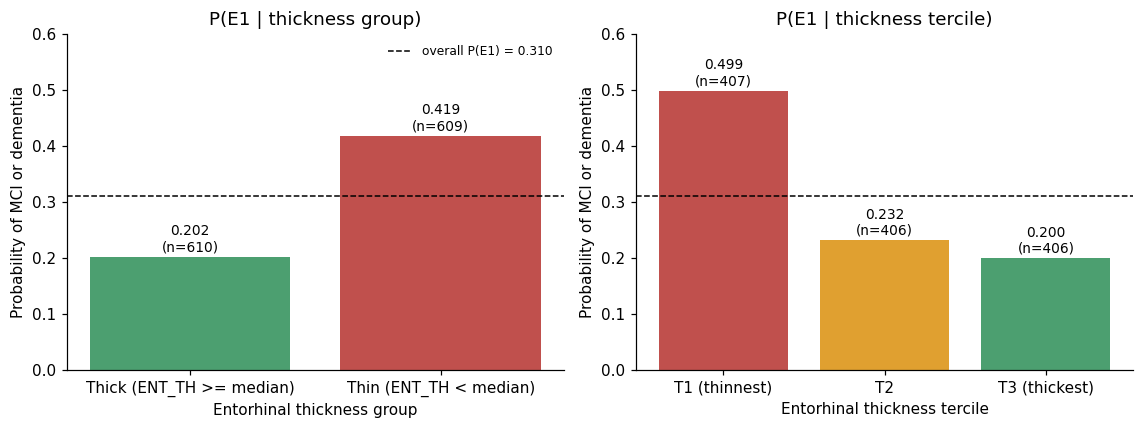

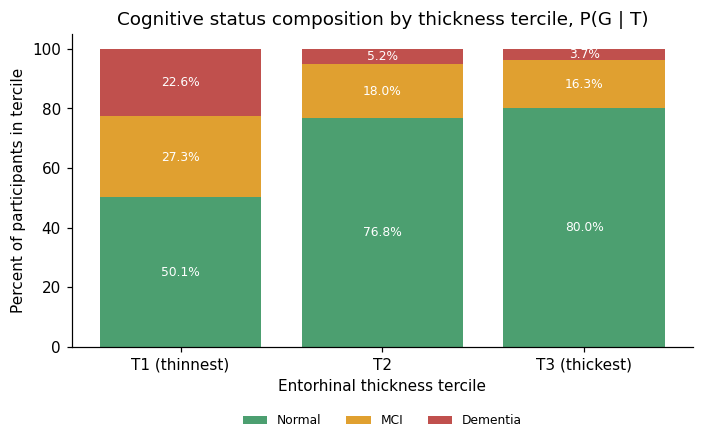

In [ ]:
# شکل ۱: احتمال اختلال شناختی به شرط ضخامت (دو سطح و سه ثلث)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
ax = axes[0]
vals = [rr["P(E1 | not L)"], rr["P(E1 | L)"]]; ns = [int((~L).sum()), int(L.sum())]
b = ax.bar(["Thick (ENT_TH >= median)", "Thin (ENT_TH < median)"], vals, color=["#4C9F70", "#C0504D"])
for bi, v, n_ in zip(b, vals, ns):
    ax.text(bi.get_x() + bi.get_width() / 2, v + 0.01, f"{v:.3f}\n(n={n_})", ha="center", fontsize=9)
ax.axhline(E1.mean(), color="k", ls="--", lw=1, label=f"overall P(E1) = {E1.mean():.3f}")
ax.set(xlabel="Entorhinal thickness group", ylabel="Probability of MCI or dementia", title="P(E1 | thickness group)", ylim=(0, 0.6)); ax.legend(frameon=False, fontsize=8)
ax = axes[1]
tv = [rr["P(E1 | T1 thinnest tercile)"], rr["P(E1 | T2)"], rr["P(E1 | T3 thickest tercile)"]]
b = ax.bar(["T1 (thinnest)", "T2", "T3 (thickest)"], tv, color=["#C0504D", "#E0A030", "#4C9F70"])
for bi, v, n_ in zip(b, tv, [int(T1.sum()), int(T2.sum()), int(T3.sum())]):
    ax.text(bi.get_x() + bi.get_width() / 2, v + 0.01, f"{v:.3f}\n(n={n_})", ha="center", fontsize=9)
ax.axhline(E1.mean(), color="k", ls="--", lw=1)
ax.set(ylabel="Probability of MCI or dementia", xlabel="Entorhinal thickness tercile", title="P(E1 | thickness tercile)", ylim=(0, 0.6))
save_fig(fig, "fig1_P_impaired_given_thickness")

# شکل ۲: ترکیب گروه شناختی در هر ثلث ضخامت (۱۰۰٪ انباشته)
pct = cond_G_given_T.T * 100
fig, ax = plt.subplots(figsize=(6.5, 4.2))
bottom = np.zeros(3)
for g_, col in zip(GROUPS, ["#4C9F70", "#E0A030", "#C0504D"]):
    ax.bar(pct.index, pct[g_], bottom=bottom, color=col, label=g_)
    for i, v in enumerate(pct[g_]):
        ax.text(i, bottom[i] + v / 2, f"{v:.1f}%", ha="center", va="center", fontsize=8, color="white")
    bottom += pct[g_].values
ax.set(xlabel="Entorhinal thickness tercile", ylabel="Percent of participants in tercile", title="Cognitive status composition by thickness tercile, P(G | T)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
save_fig(fig, "fig2_group_composition_by_tercile")

,age group,n,P(E1),n thin,P(E1 | L),n thick,P(E1 | not L),P(L)
0,<65,370,0.2432,139,0.4029,231,0.1472,0.3757
1,65-74,580,0.2759,285,0.3649,295,0.1898,0.4914
2,>=75,269,0.4758,185,0.5135,84,0.3929,0.6877


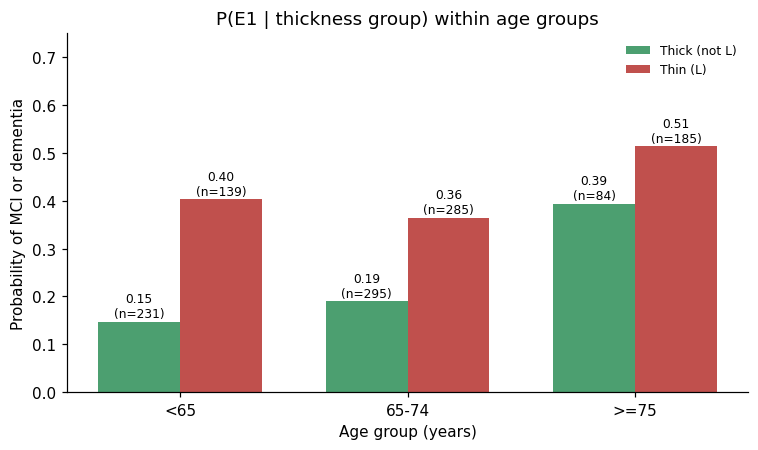

In [ ]:
# جدول و شکل ۳: کنترل ساده‌ی سن — P(E1 | L) و P(E1 | not L) در هر گروه سنی
rows = []
for a, d_ in df.groupby("AGEGRP", observed=True):
    rows.append({"age group": a, "n": len(d_), "P(E1)": d_.E1.mean(),
                 "n thin": int(d_.L.sum()), "P(E1 | L)": d_.loc[d_.L, "E1"].mean(),
                 "n thick": int((~d_.L).sum()), "P(E1 | not L)": d_.loc[~d_.L, "E1"].mean(),
                 "P(L)": d_.L.mean()})
age_tab = pd.DataFrame(rows)
display(age_tab.round(4))
save_table(age_tab, "04b_conditional_by_age_group", index=False)

fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(age_tab)); w = 0.36
b1 = ax.bar(x - w / 2, age_tab["P(E1 | not L)"], w, color="#4C9F70", label="Thick (not L)")
b2 = ax.bar(x + w / 2, age_tab["P(E1 | L)"], w, color="#C0504D", label="Thin (L)")
for bars, ns in [(b1, age_tab["n thick"]), (b2, age_tab["n thin"])]:
    for bi, n_ in zip(bars, ns):
        ax.text(bi.get_x() + bi.get_width() / 2, bi.get_height() + 0.01, f"{bi.get_height():.2f}\n(n={n_})", ha="center", fontsize=8)
ax.set_xticks(x, age_tab["age group"]); ax.set_ylim(0, 0.75)
ax.set(xlabel="Age group (years)", ylabel="Probability of MCI or dementia", title="P(E1 | thickness group) within age groups")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig3_P_impaired_by_thickness_within_age")
LEDGER.update({"P_L_by_age": age_tab.set_index("age group")["P(L)"].round(4).to_dict()})

## ۵. مفهوم استقلال (تسک ۴)

دو رویداد A و B مستقل‌اند اگر $P(A\cap B)=P(A)P(B)$، یا هم‌ارز $P(A\mid B)=P(A)$. در داده‌ی واقعی برابری دقیق انتظار نمی‌رود؛ می‌پرسیم آیا **نسبت** $\dfrac{P(A\cap B)}{P(A)P(B)}$ نزدیک ۱ است یا نه. **آزمون رسمی انجام نمی‌شود** (طبق PDF).

چهار جفت را مقایسه می‌کنیم: دو جفت بین‌وجهی (E1,L) و (M,L)، و دو جفت برای مقایسه: (F,E1) و (F,L).

In [ ]:
def indep_row(name, A, B):
    pA, pB, pAB = A.mean(), B.mean(), (A & B).mean()
    return {"pair": name, "P(A)": pA, "P(B)": pB, "P(A and B)": pAB, "P(A)P(B)": pA * pB,
            "ratio P(AB)/(P(A)P(B))": pAB / (pA * pB), "difference": pAB - pA * pB,
            "P(A | B)": (A & B).sum() / B.sum(), "P(A | not B)": (A & ~B).sum() / (~B).sum()}

indep = pd.DataFrame([
    indep_row("(E1, L): impaired vs thin cortex", E1, L),
    indep_row("(M, L): low MoCA vs thin cortex", M, L),
    indep_row("(F, E1): female vs impaired", F, E1),
    indep_row("(F, L): female vs thin cortex", F, L),
])
display(indep.round(4))
save_table(indep, "05a_independence_check", index=False)
LEDGER.update({"ratio_E1_L": indep.iloc[0]["ratio P(AB)/(P(A)P(B))"], "ratio_M_L": indep.iloc[1]["ratio P(AB)/(P(A)P(B))"],
               "ratio_F_E1": indep.iloc[2]["ratio P(AB)/(P(A)P(B))"], "ratio_F_L": indep.iloc[3]["ratio P(AB)/(P(A)P(B))"]})

# تعداد مشاهده‌شده در برابر تعداد مورد انتظار تحت استقلال (E1 × L)
obs = pd.crosstab(E1, L).reindex(index=[True, False], columns=[True, False]).to_numpy()
exp_ = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / N
cmp_counts = pd.DataFrame({"observed": obs.ravel(), "expected under independence": exp_.ravel().round(1)},
                          index=["E1 & L", "E1 & not L", "not E1 & L", "not E1 & not L"])
cmp_counts["observed / expected"] = (cmp_counts.observed / cmp_counts["expected under independence"]).round(3)
display(cmp_counts)
save_table(cmp_counts, "05b_observed_vs_expected_E1_L")

,pair,P(A),P(B),P(A and B),P(A)P(B),ratio P(AB)/(P(A)P(B)),difference,P(A | B),P(A | not B)
0,"(E1, L): impaired vs thin cortex",0.3101,0.4996,0.2092,0.1549,1.3503,0.0543,0.4187,0.2016
1,"(M, L): low MoCA vs thin cortex",0.5332,0.4996,0.3084,0.2664,1.1579,0.0421,0.6174,0.4492
2,"(F, E1): female vs impaired",0.5980,0.3101,0.1542,0.1854,0.8317,-0.0312,0.4974,0.6433
3,"(F, L): female vs thin cortex",0.5980,0.4996,0.2937,0.2988,0.9830,-0.0051,0.5878,0.6082


,observed,expected under independence,observed / expected
E1 & L,255,188.8,1.351
E1 & not L,123,189.2,0.650
not E1 & L,354,420.2,0.842
not E1 & not L,487,420.8,1.157


## ۶. توزیع گسسته و مدل دوجمله‌ای (تسک ۵)

**رویداد دودویی:** E1 (MCI یا دمانس) برای هر شرکت‌کننده. **شمارش:** $S_n$ = تعداد شرکت‌کنندگان با E1 در یک زیرنمونه‌ی تصادفی به اندازه‌ی $n$.

شرایط دوجمله‌ای $S_n\sim\text{Bin}(n,p)$: (۱) $n$ ثابت، (۲) هر آزمایش دو پیامد، (۳) $p$ در همه‌ی آزمایش‌ها ثابت، (۴) آزمایش‌ها مستقل.

روش: از ۱۲۱۹ نفر بارها زیرنمونه‌ی تصادفی **بدون جای‌گذاری** می‌کشیم، توزیع تجربی $S_n$ را می‌سازیم و با دوجمله‌ای $\text{Bin}(n,\hat p)$ و با توزیع فوق‌هندسی دقیق مقایسه می‌کنیم. بذر ثابت است.

In [ ]:
K = int(E1.sum()); p_hat = K / N
y = E1.to_numpy().astype(np.int8)

def subsample_counts(n, B=10_000, chunk=1000):
    """B زیرنمونه‌ی تصادفی بدون جای‌گذاری به اندازه‌ی n؛ تعداد E1 در هر کدام."""
    out = np.empty(B, dtype=int)
    for s in range(0, B, chunk):
        r = rng.random((chunk, N), dtype=np.float32)
        idx = np.argpartition(r, n, axis=1)[:, :n]
        out[s:s + chunk] = y[idx].sum(axis=1)
    return out

B = 10_000
sims = {n: subsample_counts(n, B) for n in (30, 300)}

rows = []
for n, cnt in sims.items():
    var_bin = n * p_hat * (1 - p_hat)
    var_hyp = stats.hypergeom(N, K, n).var()
    rows.append({"subsample size n": n, "B": B, "mean (simulated)": cnt.mean(), "n*p_hat": n * p_hat,
                 "var (simulated)": cnt.var(ddof=0), "var Binomial n*p*(1-p)": var_bin, "var Hypergeometric": var_hyp,
                 "finite-population factor (N-n)/(N-1)": (N - n) / (N - 1),
                 "var_sim / var_binomial": cnt.var(ddof=0) / var_bin})
binom_summary = pd.DataFrame(rows)
display(binom_summary.round(4))
save_table(binom_summary, "06a_binomial_summary", index=False)
LEDGER.update({"p_hat": p_hat, "binom30_var_ratio": rows[0]["var_sim / var_binomial"], "binom300_var_ratio": rows[1]["var_sim / var_binomial"],
               "fpc30": rows[0]["finite-population factor (N-n)/(N-1)"], "fpc300": rows[1]["finite-population factor (N-n)/(N-1)"]})

# جدول pmf برای n=30
n = 30
ks = np.arange(0, n + 1)
pmf_tab = pd.DataFrame({"k": ks,
                        "empirical": np.bincount(sims[30], minlength=n + 1)[:n + 1] / B,
                        "Binomial(30, p_hat)": stats.binom.pmf(ks, n, p_hat),
                        "Hypergeometric(N, K, 30)": stats.hypergeom.pmf(ks, N, K, n)})
pmf_tab["abs diff (emp - binom)"] = (pmf_tab.empirical - pmf_tab["Binomial(30, p_hat)"]).abs()
display(pmf_tab[(pmf_tab.empirical > 0) | (pmf_tab["Binomial(30, p_hat)"] > 0.001)].round(4))
save_table(pmf_tab, "06b_pmf_n30", index=False)
LEDGER["binom30_max_abs_pmf_diff"] = pmf_tab["abs diff (emp - binom)"].max()
print(f"بیشینه‌ی اختلاف مطلق pmf تجربی و دوجمله‌ای (n=30): {pmf_tab['abs diff (emp - binom)'].max():.4f}")

,subsample size n,B,mean (simulated),n*p_hat,var (simulated),var Binomial n*p*(1-p),var Hypergeometric,finite-population factor (N-n)/(N-1),var_sim / var_binomial
0,30,10000,9.2689,9.3027,6.1098,6.4180,6.2652,0.9762,0.9520
1,300,10000,93.0745,93.0271,47.7533,64.1803,48.4250,0.7545,0.7441


,k,empirical,"Binomial(30, p_hat)","Hypergeometric(N, K, 30)",abs diff (emp - binom)
2,2,0.0008,0.0013,0.0012,0.0005
3,3,0.0053,0.0054,0.0050,0.0001
4,4,0.0161,0.0163,0.0156,0.0002
5,5,0.0373,0.0381,0.0371,0.0008
6,6,0.0689,0.0714,0.0706,0.0025
7,7,0.1128,0.1100,0.1100,0.0028
8,8,0.1496,0.1421,0.1433,0.0075
9,9,0.1497,0.1562,0.1581,0.0065
10,10,0.1554,0.1474,0.1492,0.0080
11,11,0.1222,0.1205,0.1214,0.0017


بیشینه‌ی اختلاف مطلق pmf تجربی و دوجمله‌ای (n=30): 0.0080


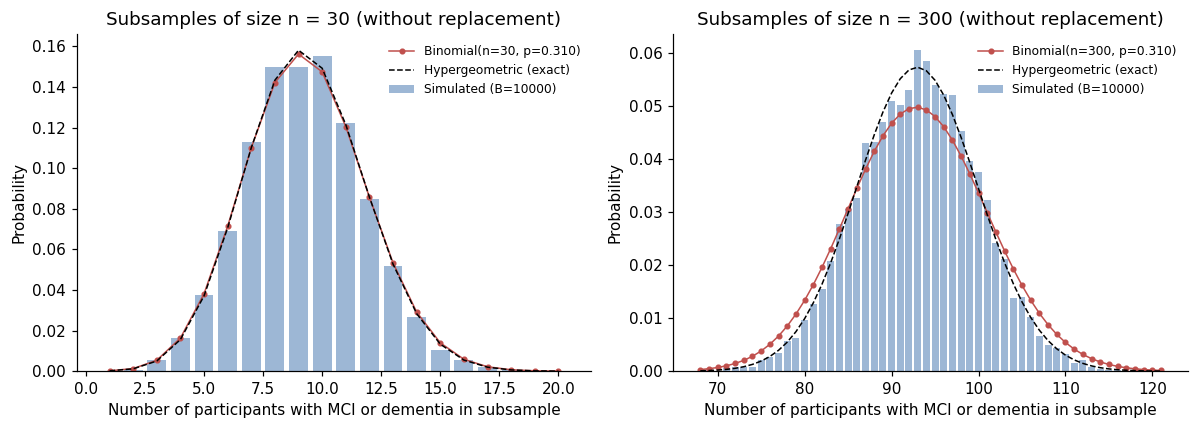

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, n in zip(axes, (30, 300)):
    cnt = sims[n]
    lo, hi = max(0, int(cnt.min()) - 1), int(cnt.max()) + 2
    ks = np.arange(lo, hi)
    emp = np.bincount(cnt, minlength=hi)[lo:hi] / B
    ax.bar(ks, emp, color="#9DB7D5", label=f"Simulated (B={B})")
    ax.plot(ks, stats.binom.pmf(ks, n, p_hat), "o-", color="#C0504D", ms=3, lw=1, label=f"Binomial(n={n}, p={p_hat:.3f})")
    ax.plot(ks, stats.hypergeom.pmf(ks, N, K, n), "k--", lw=1, label="Hypergeometric (exact)")
    ax.set(xlabel="Number of participants with MCI or dementia in subsample", ylabel="Probability", title=f"Subsamples of size n = {n} (without replacement)")
    ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig4_binomial_vs_simulated")

In [ ]:
# بررسی شرط‌های دوجمله‌ای روی داده: ثابت‌بودن p در زیرگروه‌ها
het = pd.concat([
    df.groupby("AGEGRP", observed=True).E1.agg(["size", "mean"]).rename(index=lambda a: f"age {a}"),
    df.groupby("SEX").E1.agg(["size", "mean"]).rename(index={1: "male", 2: "female"}),
]).rename(columns={"size": "n", "mean": "P(E1)"})
display(het.round(4))
save_table(het, "06c_P_E1_by_subgroup")
LEDGER.update({"P_E1_age_min": het.loc[[i for i in het.index if i.startswith("age")], "P(E1)"].min(),
               "P_E1_age_max": het.loc[[i for i in het.index if i.startswith("age")], "P(E1)"].max()})

assump = pd.DataFrame([
    ["n ثابت", "برقرار در زیرنمونه‌گیری (n را ما تعیین می‌کنیم)"],
    ["دو پیامد", "برقرار: E1 یا not E1"],
    ["p ثابت", f"در زیرنمونه‌ی تصادفی از کل نمونه p = {p_hat:.3f} ثابت است؛ ولی P(E1) بین گروه‌های سنی/جنسی فرق دارد (جدول بالا) — اگر آزمایش‌ها از یک زیرگروه خاص انتخاب شوند p ثابت نیست"],
    ["استقلال", f"نمونه‌گیری بدون جای‌گذاری از جمعیت متناهی N=1219 است؛ مستقل دقیق نیست (ضریب فوق‌هندسی: n=30 → {(N-30)/(N-1):.3f}، n=300 → {(N-300)/(N-1):.3f}). همچنین مرکز پژوهشی هر نفر در فایل نیست و خوشه‌بندی احتمالی بررسی‌پذیر نیست"],
], columns=["شرط", "وضعیت در این داده"])
display(assump)
save_table(assump, "06d_binomial_assumptions", index=False)

,n,P(E1)
age <65,370,0.2432
age 65-74,580,0.2759
age >=75,269,0.4758
male,490,0.3878
female,729,0.2579


,شرط,وضعیت در این داده
0,n ثابت,برقرار در زیرنمونه‌گیری (n را ما تعیین می‌کنیم)
1,دو پیامد,برقرار: E1 یا not E1
2,p ثابت,در زیرنمونه‌ی تصادفی از کل نمونه p = 0.310 ثاب...
3,استقلال,نمونه‌گیری بدون جای‌گذاری از جمعیت متناهی N=12...


## ۷. متغیر پیوسته و توزیع نرمال (تسک ۶؛ ج.۲)

برای $X$ (ضخامت) و $Y$ (MoCA) شکل توزیع را با هیستوگرام (با منحنی نرمال برازش‌شده با همان میانگین و انحراف معیار) و **نمودار چندک‌ـ‌چندک (QQ)** بررسی می‌کنیم. فقط به آزمون نرمال بودن بسنده نمی‌کنیم؛ این معیارها را کنار هم می‌گذاریم: چولگی، کشیدگی، پوشش تجربی در برابر قاعده‌ی ۶۸–۹۵–۹۹٫۷، مقایسه‌ی چندک‌ها و جرم نرمال بیرون از بازه‌ی ممکن.

In [ ]:
def normal_report(x, name, lower=None, upper=None):
    x = x.dropna()
    mu, sd = x.mean(), x.std(ddof=1)
    summ = {"n": len(x), "mean": mu, "median": x.median(), "sd": sd, "variance": x.var(ddof=1),
            "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x)}
    z = (x - mu) / sd
    cover = pd.DataFrame({"k (SD)": [1, 2, 3],
                          "empirical within mean±k·SD": [(z.abs() <= k).mean() for k in (1, 2, 3)],
                          "normal model": [stats.norm.cdf(k) - stats.norm.cdf(-k) for k in (1, 2, 3)]})
    cover["difference"] = cover.iloc[:, 1] - cover.iloc[:, 2]
    qs = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    quant = pd.DataFrame({"quantile": qs, "empirical": x.quantile(qs).values, "normal(mean, sd)": stats.norm.ppf(qs, mu, sd)})
    quant["difference"] = quant.empirical - quant["normal(mean, sd)"]
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    outl = {"outliers (1.5 IQR rule)": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
            "low side": int((x < q1 - 1.5 * iqr).sum()), "high side": int((x > q3 + 1.5 * iqr).sum()),
            "|z| > 3": int((z.abs() > 3).sum())}
    return summ, cover, quant, outl

sX, cX, qX, oX = normal_report(df.ENT_TH, "X")
sY, cY, qY, oY = normal_report(df.MOCA, "Y")

print("=== X = mean entorhinal thickness (mm) ===")
display(pd.Series(sX).round(4).to_frame("value").T); display(cX.round(4)); display(qX.round(4)); print(oX)
print("\n=== Y = MoCA (points) ===")
display(pd.Series(sY).round(4).to_frame("value").T); display(cY.round(4)); display(qY.round(4)); print(oY)

shape_tab = pd.DataFrame({"X (ENT_TH, mm)": sX, "Y (MoCA)": sY}).T
shape_tab = pd.concat([shape_tab, pd.DataFrame({"X (ENT_TH, mm)": oX, "Y (MoCA)": oY}).T], axis=1)
save_table(shape_tab.round(4), "07a_shape_summary_X_Y")
save_table(cX, "07b_coverage_X", index=False); save_table(cY, "07b_coverage_Y", index=False)
save_table(qX, "07c_quantiles_X", index=False); save_table(qY, "07c_quantiles_Y", index=False)

# حرکت منحنی نرمال خارج از بازه‌ی ممکن MoCA و سقف ۳۰
muY, sdY = sY["mean"], sY["sd"]
mass_out = stats.norm.cdf(-0.5, muY, sdY) + stats.norm.sf(30.5, muY, sdY)
p30_emp = (df.MOCA >= 29.5).mean(); p30_norm = stats.norm.sf(29.5, muY, sdY)
print(f"\nجرم مدل نرمال بیرون از بازه‌ی ممکن [0,30] برای MoCA: {mass_out:.4f}")
print(f"P(MoCA >= 29.5): تجربی = {p30_emp:.4f} | مدل نرمال = {p30_norm:.4f}")
# مثال احتمال: P(X < 2.5 mm)
c = 2.5
print(f"P(X < {c} mm): تجربی = {(df.ENT_TH < c).mean():.4f} | تقریب نرمال = {stats.norm.cdf(c, sX['mean'], sX['sd']):.4f}")
LEDGER.update({"X_mean": sX["mean"], "X_sd": sX["sd"], "X_skew": sX["skewness"], "X_kurt": sX["excess kurtosis"],
               "X_cover1": cX.iloc[0, 1], "X_cover2": cX.iloc[1, 1], "X_cover3": cX.iloc[2, 1],
               "Y_mean": sY["mean"], "Y_sd": sY["sd"], "Y_skew": sY["skewness"], "Y_kurt": sY["excess kurtosis"],
               "Y_cover1": cY.iloc[0, 1], "Y_cover2": cY.iloc[1, 1], "Y_cover3": cY.iloc[2, 1],
               "Y_mass_out": mass_out, "Y_p30_emp": p30_emp, "Y_p30_norm": p30_norm,
               "X_outliers": oX["outliers (1.5 IQR rule)"], "Y_outliers": oY["outliers (1.5 IQR rule)"],
               "X_P_lt_2_5_emp": (df.ENT_TH < c).mean(), "X_P_lt_2_5_norm": stats.norm.cdf(c, sX["mean"], sX["sd"])})

=== X = mean entorhinal thickness (mm) ===


,n,mean,median,sd,variance,skewness,excess kurtosis
value,1219.0,3.0142,3.0575,0.3559,0.1267,-0.8254,1.7664


,k (SD),empirical within mean±k·SD,normal model,difference
0,1,0.7104,0.6827,0.0277
1,2,0.9565,0.9545,0.0020
2,3,0.9910,0.9973,-0.0063


,quantile,empirical,"normal(mean, sd)",difference
0,0.01,2.0504,2.1863,-0.1360
1,0.05,2.3740,2.4289,-0.0549
2,0.25,2.8050,2.7742,0.0308
3,0.50,3.0575,3.0142,0.0433
4,0.75,3.2513,3.2543,-0.0030
5,0.95,3.5262,3.5996,-0.0734
6,0.99,3.6784,3.8422,-0.1638


{'outliers (1.5 IQR rule)': 24, 'low side': 23, 'high side': 1, '|z| > 3': 11}

=== Y = MoCA (points) ===


,n,mean,median,sd,variance,skewness,excess kurtosis
value,1219.0,24.3838,25.4,4.4348,19.6672,-1.8259,4.5116


,k (SD),empirical within mean±k·SD,normal model,difference
0,1,0.7818,0.6827,0.0991
1,2,0.9516,0.9545,-0.0029
2,3,0.9737,0.9973,-0.0236


,quantile,empirical,"normal(mean, sd)",difference
0,0.01,8.0,14.0669,-6.0669
1,0.05,16.0,17.0892,-1.0892
2,0.25,23.0,21.3925,1.6075
3,0.50,25.4,24.3838,1.0162
4,0.75,27.0,27.3750,-0.3750
5,0.95,29.0,31.6783,-2.6783
6,0.99,30.0,34.7006,-4.7006


{'outliers (1.5 IQR rule)': 76, 'low side': 76, 'high side': 0, '|z| > 3': 32}

جرم مدل نرمال بیرون از بازه‌ی ممکن [0,30] برای MoCA: 0.0839
P(MoCA >= 29.5): تجربی = 0.0386 | مدل نرمال = 0.1243
P(X < 2.5 mm): تجربی = 0.0788 | تقریب نرمال = 0.0742


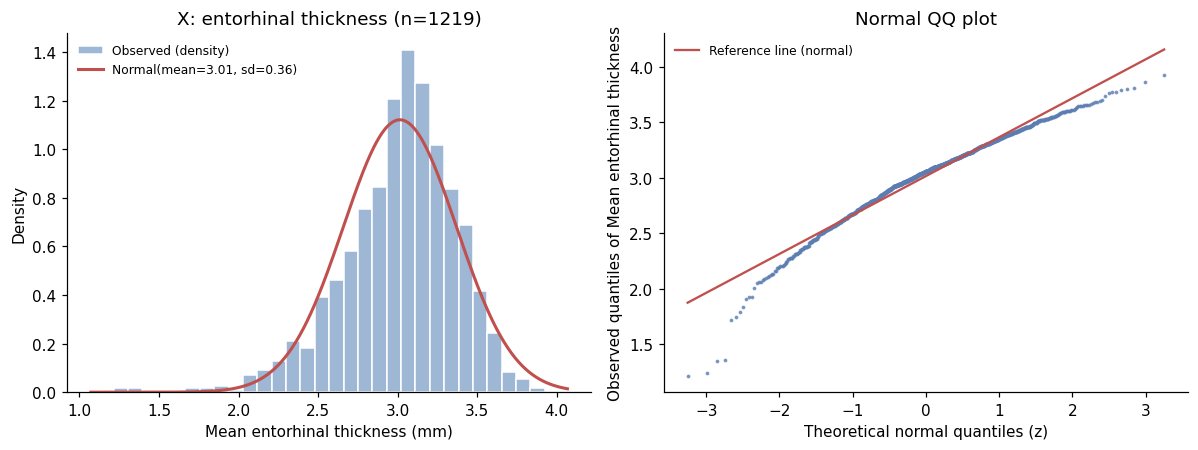

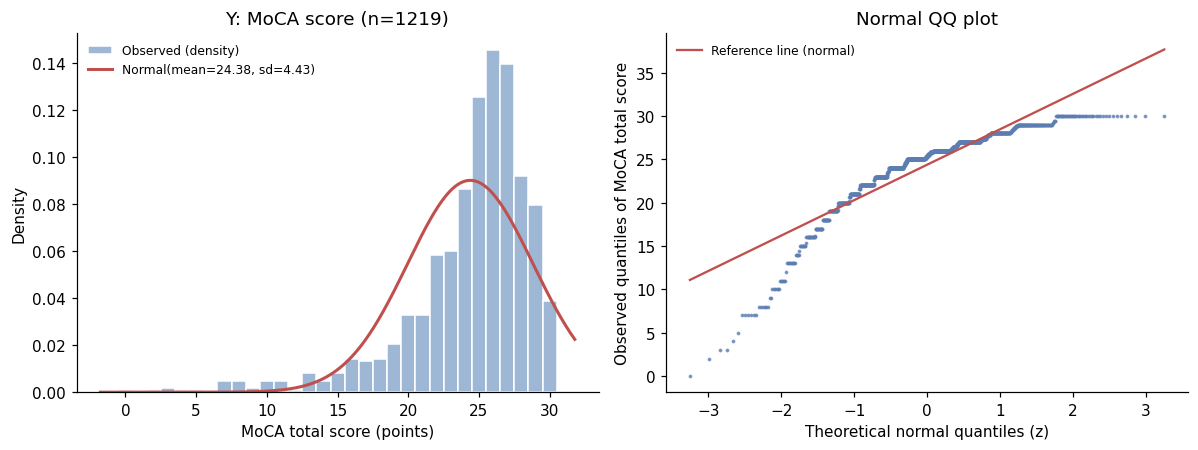

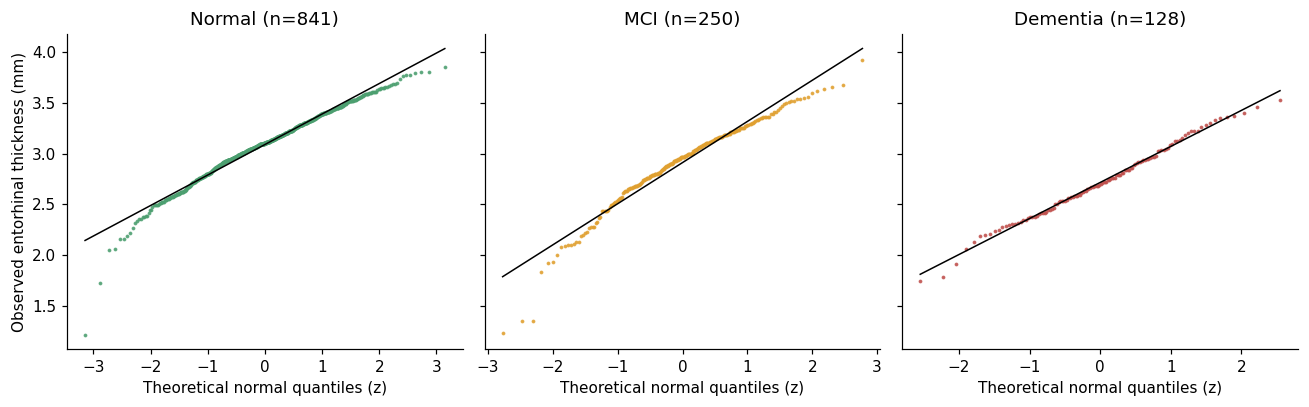

,n,mean,sd,skewness,excess_kurtosis
GROUP,,,,,
Normal,841,3.090,0.303,-0.680,2.075
MCI,250,2.912,0.412,-0.942,1.807
Dementia,128,2.716,0.352,-0.032,-0.107


In [ ]:
def hist_qq(x, xlabel, title, fname, bins, integer_bins=False):
    x = x.dropna(); mu, sd = x.mean(), x.std(ddof=1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ax = axes[0]
    ax.hist(x, bins=bins, density=True, color="#9DB7D5", edgecolor="white", label="Observed (density)")
    g = np.linspace(x.min() - 2 * sd * 0.2, x.max() + 2 * sd * 0.2, 400)
    ax.plot(g, stats.norm.pdf(g, mu, sd), color="#C0504D", lw=2, label=f"Normal(mean={mu:.2f}, sd={sd:.2f})")
    ax.set(xlabel=xlabel, ylabel="Density", title=title); ax.legend(frameon=False, fontsize=8)
    ax = axes[1]
    (osm, osr), (slope, intercept, r) = stats.probplot(x, dist="norm")
    ax.plot(osm, osr, ".", ms=3, color="#5B7DB1", alpha=.7)
    ax.plot(osm, slope * np.asarray(osm) + intercept, color="#C0504D", lw=1.5, label="Reference line (normal)")
    ax.set(xlabel="Theoretical normal quantiles (z)", ylabel=f"Observed quantiles of {xlabel.split(' (')[0]}", title="Normal QQ plot")
    ax.legend(frameon=False, fontsize=8)
    save_fig(fig, fname)

hist_qq(df.ENT_TH, "Mean entorhinal thickness (mm)", f"X: entorhinal thickness (n={N})", "fig5_X_hist_normal_qq", 30)
hist_qq(df.MOCA, "MoCA total score (points)", f"Y: MoCA score (n={N})", "fig6_Y_hist_normal_qq", np.arange(-0.5, 31.5, 1))

# QQ جداگانه‌ی ضخامت در هر گروه
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, g_, col in zip(axes, GROUPS, ["#4C9F70", "#E0A030", "#C0504D"]):
    xg = df.loc[df.GROUP == g_, "ENT_TH"]
    (osm, osr), (slope, intercept, r) = stats.probplot(xg, dist="norm")
    ax.plot(osm, osr, ".", ms=3, color=col, alpha=.8); ax.plot(osm, slope * np.asarray(osm) + intercept, "k", lw=1)
    ax.set(xlabel="Theoretical normal quantiles (z)", title=f"{g_} (n={len(xg)})")
axes[0].set_ylabel("Observed entorhinal thickness (mm)")
save_fig(fig, "fig7_X_qq_by_group")

grp_shape = df.groupby("GROUP", observed=True).ENT_TH.agg(n="size", mean="mean", sd="std", skewness=lambda s: stats.skew(s), excess_kurtosis=lambda s: stats.kurtosis(s)).round(3)
display(grp_shape); save_table(grp_shape, "07d_X_shape_by_group")

## ۸. امید ریاضی و واریانس (تسک ۷؛ ج.۲)

برای توزیع تجربی $x_1,\dots,x_N$ هر مشاهده احتمال $1/N$ دارد:
$$E[X]=\sum_i x_i\frac1N=\bar x,\qquad \operatorname{Var}(X)=E\big[(X-E[X])^2\big]$$
(در این بخش واریانس **توزیع تجربی** با مقسوم‌علیه $N$ است تا اتحادهای دقیق برقرار شوند؛ واریانس نمونه با مقسوم‌علیه $N-1$ هم گزارش می‌شود.)

In [ ]:
def ev_table(x, name, unit):
    x = x.dropna()
    return {"variable": name, "unit": unit, "E[.] = mean": x.mean(), "Var (empirical, /N)": x.var(ddof=0),
            "Var (sample, /(N-1))": x.var(ddof=1), "SD (sample)": x.std(ddof=1)}

evt = pd.DataFrame([ev_table(df.ENT_TH, "X = entorhinal thickness", "mm (variance: mm^2)"),
                    ev_table(df.MOCA, "Y = MoCA", "points (variance: points^2)"),
                    ev_table(df.NACCAGE, "Age", "years (variance: years^2)")])
display(evt.round(4)); save_table(evt, "08a_expectation_variance", index=False)

# تعریف مستقیم E[Y] = sum y p(y) روی مقادیر مشاهده‌شده
pmfY = df.MOCA.value_counts(normalize=True).sort_index()
EY = (pmfY.index.to_numpy() * pmfY.to_numpy()).sum()
VarY = (((pmfY.index.to_numpy() - EY) ** 2) * pmfY.to_numpy()).sum()
assert np.isclose(EY, df.MOCA.mean()) and np.isclose(VarY, df.MOCA.var(ddof=0))
print(f"E[Y] = sum y*p(y) = {EY:.4f}  (برابر میانگین)   Var(Y) = {VarY:.4f}   (تعداد مقادیر متمایز: {len(pmfY)})")

# متغیر برنولی I(E1): E = p، Var = p(1-p)
p_ = E1.mean()
print(f"I(E1): E = {E1.astype(int).mean():.4f} = p | Var = {E1.astype(int).var(ddof=0):.4f} = p(1-p) = {p_*(1-p_):.4f}")
# شمارش دوجمله‌ای n=30: E = np، Var = np(1-p)
print(f"Binomial(30, p_hat): E = {30*p_hat:.3f} | Var = {30*p_hat*(1-p_hat):.3f} | شبیه‌سازی: mean = {sims[30].mean():.3f}, var = {sims[30].var():.3f}")
LEDGER.update({"EX": df.ENT_TH.mean(), "VarX_pop": df.ENT_TH.var(ddof=0), "VarX_smp": df.ENT_TH.var(ddof=1),
               "EY": EY, "VarY_pop": VarY, "VarY_smp": df.MOCA.var(ddof=1)})

,variable,unit,E[.] = mean,"Var (empirical, /N)","Var (sample, /(N-1))",SD (sample)
0,X = entorhinal thickness,mm (variance: mm^2),3.0142,0.1266,0.1267,0.3559
1,Y = MoCA,points (variance: points^2),24.3838,19.6511,19.6672,4.4348
2,Age,years (variance: years^2),68.1723,65.2583,65.3118,8.0816


E[Y] = sum y*p(y) = 24.3838  (برابر میانگین)   Var(Y) = 19.6511   (تعداد مقادیر متمایز: 67)
I(E1): E = 0.3101 = p | Var = 0.2139 = p(1-p) = 0.2139
Binomial(30, p_hat): E = 9.303 | Var = 6.418 | شبیه‌سازی: mean = 9.269, var = 6.110


In [ ]:
# امید و واریانس شرطی و اتحادهای امید کل / واریانس کل
pg = df.GROUP.value_counts(normalize=True).reindex(GROUPS)
rows = []
for var, lab in [("ENT_TH", "X = entorhinal thickness (mm)"), ("MOCA", "Y = MoCA (points)")]:
    gstats = df.groupby("GROUP", observed=True)[var].agg(["mean", lambda s: s.var(ddof=0)]).reindex(GROUPS)
    gstats.columns = ["E[.|G]", "Var(.|G)"]
    mu = df[var].mean()
    E_cond_var = (pg * gstats["Var(.|G)"]).sum()               # E[Var(.|G)]
    Var_cond_mean = (pg * (gstats["E[.|G]"] - mu) ** 2).sum()  # Var(E[.|G])
    total = df[var].var(ddof=0)
    assert np.isclose(E_cond_var + Var_cond_mean, total)
    assert np.isclose((pg * gstats["E[.|G]"]).sum(), mu)
    print(f"\n{lab}"); display(gstats.assign(P_G=pg).round(4))
    rows.append({"variable": lab, "E[Var(.|G)] (within groups)": E_cond_var, "Var(E[.|G]) (between groups)": Var_cond_mean,
                 "total Var": total, "between / total": Var_cond_mean / total})
    save_table(gstats.assign(P_G=pg), f"08b_conditional_moments_{var}")
decomp = pd.DataFrame(rows)
display(decomp.round(4)); save_table(decomp, "08c_law_of_total_variance", index=False)
LEDGER.update({"X_between_frac": decomp.iloc[0]["between / total"], "Y_between_frac": decomp.iloc[1]["between / total"]})


X = entorhinal thickness (mm)


,E[.|G],Var(.|G),P_G
GROUP,,,
Normal,3.0901,0.0920,0.6899
MCI,2.9120,0.1694,0.2051
Dementia,2.7158,0.1227,0.1050



Y = MoCA (points)


,E[.|G],Var(.|G),P_G
GROUP,,,
Normal,26.1767,5.5858,0.6899
MCI,22.3992,11.4005,0.2051
Dementia,16.4797,36.8915,0.1050


,variable,E[Var(.|G)] (within groups),Var(E[.|G]) (between groups),total Var,between / total
0,X = entorhinal thickness (mm),0.1111,0.0155,0.1266,0.1222
1,Y = MoCA (points),10.0655,9.5856,19.6511,0.4878


## ۹. دو متغیر تصادفی و کوواریانس (تسک ۸؛ ج.۴)

$$\operatorname{Cov}(X,Y)=E\big[(X-E[X])(Y-E[Y])\big]$$

علامت کوواریانس جهت رابطه‌ی خطی را نشان می‌دهد؛ مقدار آن به واحدها وابسته است (mm·امتیاز)، پس برای شدت رابطه مقیاس‌بی‌بعدی لازم است که **همبستگی رسمی و استنباط آن در فاز ۴** می‌آید. از این رابطه نتیجه‌ی علّی گرفته نمی‌شود.

In [ ]:
V = df[["ENT_TH", "MOCA", "NACCAGE"]]
cov_s = V.cov()                                  # کوواریانس نمونه (/(N-1))
display(cov_s.round(4)); save_table(cov_s.round(5), "09a_covariance_matrix")
cXY = cov_s.loc["ENT_TH", "MOCA"]
print(f"Cov(X, Y) = {cXY:.4f} mm*points -> {'مثبت' if cXY > 0 else 'منفی'}")
print(f"Cov(X, Age) = {cov_s.loc['ENT_TH','NACCAGE']:.4f} | Cov(Y, Age) = {cov_s.loc['MOCA','NACCAGE']:.4f}")
LEDGER.update({"CovXY": cXY, "CovXAge": cov_s.loc["ENT_TH", "NACCAGE"], "CovYAge": cov_s.loc["MOCA", "NACCAGE"]})

# قانون کوواریانس کل: Cov = E[Cov(.,.|G)] + Cov(E[X|G], E[Y|G])  (با مقسوم‌علیه N)
rows = []
for g_ in GROUPS:
    dg = df[df.GROUP == g_]
    rows.append({"group": g_, "n": len(dg), "Cov(X,Y | G)": np.cov(dg.ENT_TH, dg.MOCA, ddof=1)[0, 1]})
cov_by_group = pd.DataFrame(rows)
pg_ = df.GROUP.value_counts(normalize=True).reindex(GROUPS)
within = sum(pg_[g_] * np.cov(df[df.GROUP == g_].ENT_TH, df[df.GROUP == g_].MOCA, ddof=0)[0, 1] for g_ in GROUPS)
mX = df.groupby("GROUP", observed=True).ENT_TH.mean().reindex(GROUPS); mY = df.groupby("GROUP", observed=True).MOCA.mean().reindex(GROUPS)
between = (pg_ * (mX - df.ENT_TH.mean()) * (mY - df.MOCA.mean())).sum()
total = np.cov(df.ENT_TH, df.MOCA, ddof=0)[0, 1]
assert np.isclose(within + between, total)
display(cov_by_group.round(4))
dec = pd.DataFrame([{"within groups E[Cov(X,Y|G)]": within, "between groups Cov(E[X|G],E[Y|G])": between, "total Cov(X,Y) (/N)": total, "between / total": between / total}])
display(dec.round(4))
save_table(cov_by_group, "09b_covariance_by_group", index=False); save_table(dec, "09c_total_covariance_decomposition", index=False)
LEDGER.update({"Cov_within": within, "Cov_between": between, "Cov_total_N": total, "Cov_between_frac": between / total})

,ENT_TH,MOCA,NACCAGE
ENT_TH,0.1267,0.4849,-0.7668
MOCA,0.4849,19.6672,-5.9074
NACCAGE,-0.7668,-5.9074,65.3118


Cov(X, Y) = 0.4849 mm*points -> مثبت
Cov(X, Age) = -0.7668 | Cov(Y, Age) = -5.9074


,group,n,"Cov(X,Y | G)"
0,Normal,841,0.0744
1,MCI,250,0.2207
2,Dementia,128,0.0483


,"within groups E[Cov(X,Y|G)]","between groups Cov(E[X|G],E[Y|G])","total Cov(X,Y) (/N)",between / total
0,0.1014,0.3831,0.4845,0.7907


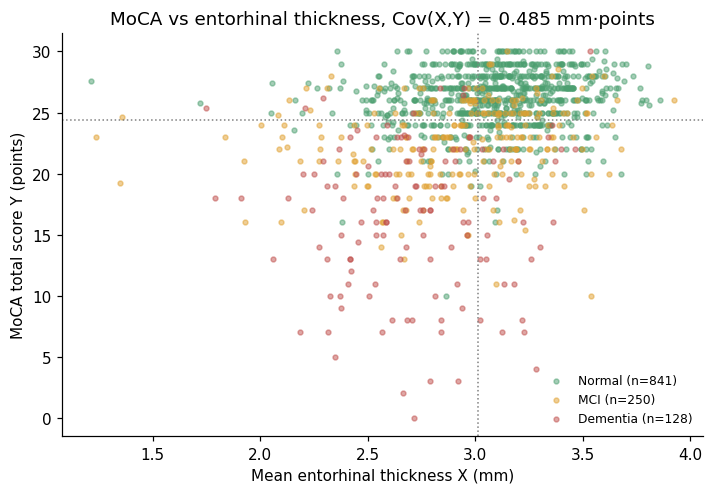

,thickness_mean,moca_mean,n
ENT_TH,,,
"(1.213, 2.559]",2.304,21.289,122
"(2.559, 2.747]",2.657,22.202,122
"(2.747, 2.88]",2.812,23.275,122
"(2.88, 2.97]",2.931,24.548,122
"(2.97, 3.058]",3.016,25.189,123
"(3.058, 3.125]",3.093,25.266,121
"(3.125, 3.206]",3.165,25.431,122
"(3.206, 3.302]",3.254,24.815,122
"(3.302, 3.427]",3.362,25.856,121


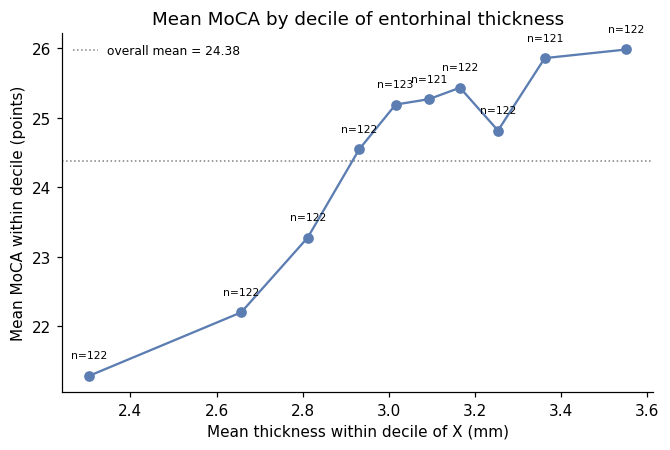

In [ ]:
# شکل ۸: پراکنش MoCA بر حسب ضخامت (به تفکیک گروه) + شکل ۹: میانگین MoCA در دهک‌های ضخامت
COL = {"Normal": "#4C9F70", "MCI": "#E0A030", "Dementia": "#C0504D"}
fig, ax = plt.subplots(figsize=(6.6, 4.6))
for g_ in GROUPS:
    s = df[df.GROUP == g_]
    ax.scatter(s.ENT_TH, s.MOCA, s=10, alpha=.5, color=COL[g_], label=f"{g_} (n={len(s)})")
ax.axvline(df.ENT_TH.mean(), color="gray", ls=":", lw=1); ax.axhline(df.MOCA.mean(), color="gray", ls=":", lw=1)
ax.set(xlabel="Mean entorhinal thickness X (mm)", ylabel="MoCA total score Y (points)",
       title=f"MoCA vs entorhinal thickness, Cov(X,Y) = {cXY:.3f} mm·points")
ax.legend(frameon=False, fontsize=8, loc="lower right")
save_fig(fig, "fig8_scatter_thickness_moca_covariance")

dec_ = pd.qcut(df.ENT_TH, 10)
dtab = df.groupby(dec_, observed=True).agg(thickness_mean=("ENT_TH", "mean"), moca_mean=("MOCA", "mean"), n=("MOCA", "size"))
display(dtab.round(3)); save_table(dtab.round(4), "09d_decile_means")
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot(dtab.thickness_mean, dtab.moca_mean, "o-", color="#5B7DB1")
for xx, yy, nn in zip(dtab.thickness_mean, dtab.moca_mean, dtab.n):
    ax.text(xx, yy + 0.25, f"n={nn}", ha="center", fontsize=7)
ax.axhline(df.MOCA.mean(), color="gray", ls=":", lw=1, label=f"overall mean = {df.MOCA.mean():.2f}")
ax.set(xlabel="Mean thickness within decile of X (mm)", ylabel="Mean MoCA within decile (points)", title="Mean MoCA by decile of entorhinal thickness")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig9_mean_moca_by_thickness_decile")

## ۱۰. قضیه‌ی بیز (تسک ۹)

ساختار مسئله برای به‌روزرسانی احتمال مناسب است: احتمال پیشین اختلال شناختی $P(E1)$ را با شاهد «ضخامت کم» یا «MoCA پایین» به احتمال پسین تبدیل می‌کنیم:
$$P(E1\mid L)=\frac{P(L\mid E1)\,P(E1)}{P(L\mid E1)\,P(E1)+P(L\mid \neg E1)\,P(\neg E1)}$$

همه‌ی احتمال‌ها از فراوانی‌های تجربی همین نمونه می‌آیند. نتیجه‌ی فرمول باید با شمارش مستقیم **دقیقاً** برابر باشد (کنترل).

In [ ]:
def bayes_post(prior, p_e_given_h, p_e_given_not_h):
    num = p_e_given_h * prior
    return num / (num + p_e_given_not_h * (1 - prior))

prior = E1.mean()
# --- الف) ضخامت کم به‌عنوان شاهد ---
sensL = L[E1].mean()            # P(L | E1)
fprL = L[~E1].mean()            # P(L | not E1)
postL = bayes_post(prior, sensL, fprL)                      # P(E1 | L)
postnotL = bayes_post(prior, 1 - sensL, 1 - fprL)           # P(E1 | not L)
assert np.isclose(postL, E1[L].mean()) and np.isclose(postnotL, E1[~L].mean())

# --- ب) MoCA < 26 به‌عنوان آزمون غربالگری ---
sensM = M[E1].mean(); specM = (~M)[~E1].mean(); fprM = 1 - specM
postM = bayes_post(prior, sensM, fprM)                      # PPV
negM = bayes_post(prior, 1 - sensM, 1 - fprM)               # P(E1 | not M) = 1 - NPV
assert np.isclose(postM, E1[M].mean()) and np.isclose(negM, E1[~M].mean())

bayes_tab = pd.DataFrame([
    ["Evidence L (thin entorhinal cortex)", prior, sensL, fprL, postL, postnotL],
    ["Evidence M (MoCA < 26)", prior, sensM, fprM, postM, negM],
], columns=["evidence", "prior P(E1)", "P(evidence | E1)", "P(evidence | not E1)", "posterior P(E1 | evidence)", "P(E1 | no evidence)"])
display(bayes_tab.round(4)); save_table(bayes_tab, "10a_bayes_updates", index=False)
print(f"نسبت درست‌نمایی مثبت LR+ برای L: {sensL / fprL:.3f} | برای M: {sensM / fprM:.3f}")
LEDGER.update({"sensL": sensL, "fprL": fprL, "postL": postL, "postnotL": postnotL, "LRposL": sensL / fprL,
               "sensM": sensM, "specM": specM, "PPV_M": postM, "NPV_M": 1 - negM, "LRposM": sensM / fprM})

,evidence,prior P(E1),P(evidence | E1),P(evidence | not E1),posterior P(E1 | evidence),P(E1 | no evidence)
0,Evidence L (thin entorhinal cortex),0.3101,0.6746,0.4209,0.4187,0.2016
1,Evidence M (MoCA < 26),0.3101,0.8757,0.3793,0.5092,0.0826


نسبت درست‌نمایی مثبت LR+ برای L: 1.603 | برای M: 2.309


,assumed prevalence P(E1),PPV of MoCA<26: P(E1 | M),NPV of MoCA<26: P(not E1 | not M),note
0,0.0200,0.0450,0.9959,hypothetical
1,0.0500,0.1083,0.9896,hypothetical
2,0.1000,0.2041,0.9782,hypothetical
3,0.2000,0.3659,0.9523,hypothetical
4,0.3101,0.5092,0.9174,this sample
5,0.5000,0.6978,0.8331,hypothetical


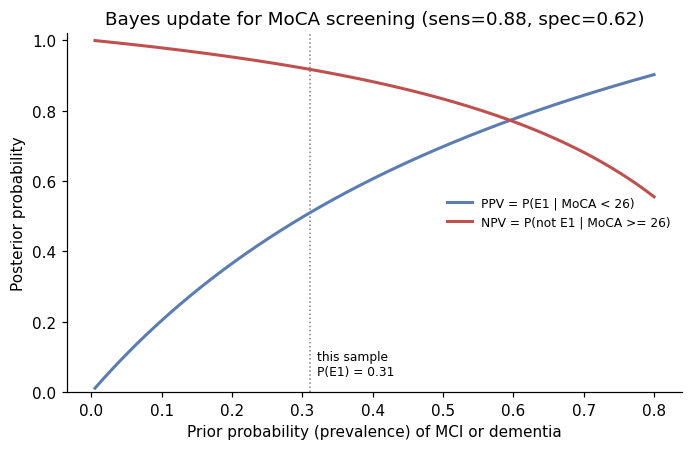

,evidence,"sequential Bayes (assumes L, M independent given E1)",direct empirical P(E1 | evidence),n,difference
0,L and M (both present),0.6245,0.6090,376,0.0154
1,not L and not M (both absent),0.0482,0.0625,336,-0.0143


In [ ]:
# --- ج) حساسیت PPV به شیوع پیشین (فرض‌های فرضی با همان حساسیت و ویژگی) ---
prev_grid = np.array([0.02, 0.05, 0.10, 0.20, prior, 0.50])
ppv_tab = pd.DataFrame({"assumed prevalence P(E1)": prev_grid,
                        "PPV of MoCA<26: P(E1 | M)": bayes_post(prev_grid, sensM, fprM),
                        "NPV of MoCA<26: P(not E1 | not M)": 1 - bayes_post(prev_grid, 1 - sensM, 1 - fprM)})
ppv_tab["note"] = ["hypothetical"] * 4 + ["this sample"] + ["hypothetical"]
display(ppv_tab.round(4)); save_table(ppv_tab, "10b_ppv_vs_prevalence", index=False)
LEDGER.update({"PPV_at_5pct": float(bayes_post(0.05, sensM, fprM)), "PPV_at_10pct": float(bayes_post(0.10, sensM, fprM))})

gp = np.linspace(0.005, 0.8, 200)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(gp, bayes_post(gp, sensM, fprM), color="#5B7DB1", lw=2, label="PPV = P(E1 | MoCA < 26)")
ax.plot(gp, 1 - bayes_post(gp, 1 - sensM, 1 - fprM), color="#C0504D", lw=2, label="NPV = P(not E1 | MoCA >= 26)")
ax.axvline(prior, color="gray", ls=":", lw=1); ax.text(prior + 0.01, 0.05, f"this sample\nP(E1) = {prior:.2f}", fontsize=8)
ax.set(xlabel="Prior probability (prevalence) of MCI or dementia", ylabel="Posterior probability", title=f"Bayes update for MoCA screening (sens={sensM:.2f}, spec={specM:.2f})", ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=8, loc="center right")
save_fig(fig, "fig10_ppv_npv_vs_prevalence")

# --- د) به‌روزرسانی متوالی با دو شاهد (فرض استقلال شرطی) در برابر شمارش مستقیم ---
prior_odds = prior / (1 - prior)
post_odds_both = prior_odds * (sensL / fprL) * (sensM / fprM)
naive_both = post_odds_both / (1 + post_odds_both)                     # P(E1 | L, M) با فرض استقلال شرطی
direct_both = E1[L & M].mean()
prior_odds_neg = prior_odds * ((1 - sensL) / (1 - fprL)) * ((1 - sensM) / (1 - fprM))
naive_neither = prior_odds_neg / (1 + prior_odds_neg)
direct_neither = E1[~L & ~M].mean()
seq = pd.DataFrame([["L and M (both present)", naive_both, direct_both, int((L & M).sum())],
                    ["not L and not M (both absent)", naive_neither, direct_neither, int((~L & ~M).sum())]],
                   columns=["evidence", "sequential Bayes (assumes L, M independent given E1)", "direct empirical P(E1 | evidence)", "n"])
seq["difference"] = seq.iloc[:, 1] - seq.iloc[:, 2]
display(seq.round(4)); save_table(seq, "10c_sequential_bayes_vs_direct", index=False)
LEDGER.update({"naive_both": naive_both, "direct_both": direct_both, "naive_neither": naive_neither, "direct_neither": direct_neither})

## ۱۱. خلاصه‌ی اعداد کلیدی و ذخیره‌ی خروجی‌ها

In [ ]:
ledger_df = pd.DataFrame([(k, (float(v) if np.isscalar(v) else str(v))) for k, v in LEDGER.items()], columns=["key", "value"])
display(ledger_df.round(5))
save_table(ledger_df, "11_key_numbers_ledger", index=False)

import shutil
shutil.make_archive("phase2_outputs", "zip", OUT_DIR)
print("ساخته شد: phase2_outputs.zip")
try:
    from google.colab import files
    files.download("phase2_outputs.zip")
except ImportError:
    pass

,key,value
0,N_merged,1237.0
1,N,1219.0
2,TH_MEDIAN,3.0575
3,P_E1,0.31009
4,P_D,0.105004
...,...,...
88,PPV_at_10pct,0.204143
89,naive_both,0.624476
90,direct_both,0.609043
91,naive_neither,0.048158


ساخته شد: phase2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>